In [97]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score,r2_score
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer,SimpleImputer
from sklearn.pipeline import Pipeline
import seaborn as sns

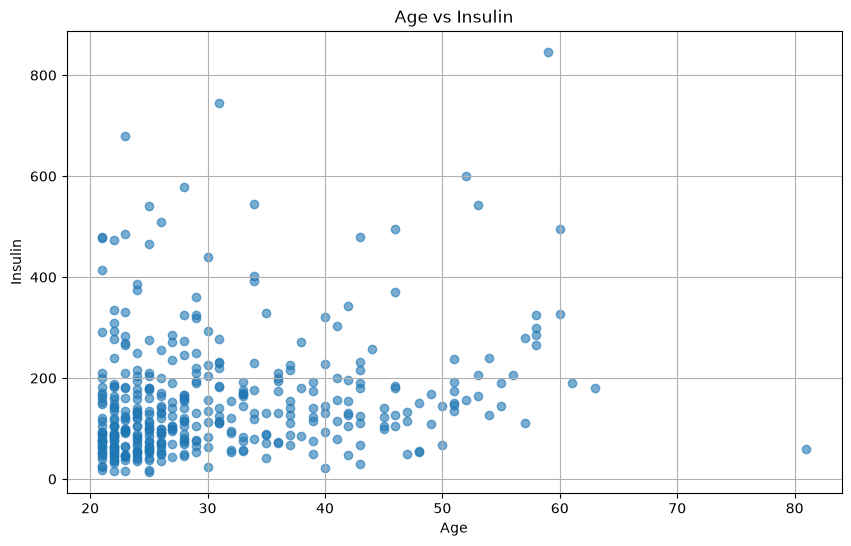

"plt.figure(figsize=(10, 6))\nplt.scatter(\n    df_new[df_new['Insulin'] != 0]['Age'],\n    df_new[df_new['Insulin'] != 0]['Insulin'],\n    alpha=0.6\n)\nplt.xlabel('Age')\nplt.ylabel('Insulin')\nplt.title('Age vs Insulin')\nplt.grid(True)\nplt.show()\ndf_new.describe()"

In [ ]:
#from iris_Knn_soham import Y_test


df=pd.read_csv('diabetes.csv')
df_copy=df.copy()
#df_copy.head()
#df_copy['Insulin']=df_copy['Insulin'].replace(0,np.nan)
#X=df_copy[['Pregnancies','Glucose','BMI','Age']]
#Y=df_copy['Insulin']
#train=df_copy[df_copy['Insulin'].notnull()]
#test=df_copy[df_copy['Insulin'].isnull()]
#train.head()
#Age V/S Insulin
plt.figure(figsize=(10, 6))
plt.scatter(
    df[df['Insulin'] != 0]['Age'],
    df[df['Insulin'] != 0]['Insulin'],
    alpha=0.6
)
plt.xlabel('Age')
plt.ylabel('Insulin')
plt.title('Age vs Insulin')
plt.grid(True)
plt.show()
col_1=['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
def remove_outliers(df, col_1):
    df_copy=df.copy() 
    for col in col_1:
     q1 = df_copy[col].quantile(0.25)
     q3 = df_copy[col].quantile(0.75)
     IQR = q3 - q1
     low = q1 - 1.5 * IQR
     upp = q3 + 1.5 * IQR
     df_copy = df_copy[
        (df_copy[col] >= low) &
        (df_copy[col] <= upp)
     ]
    return df_copy
col_1 = [
    'Pregnancies', 'Glucose', 'BloodPressure',
    'SkinThickness', 'Insulin', 'BMI',
    'DiabetesPedigreeFunction', 'Age'
]

df_new = remove_outliers(df_copy, col_1)
df_new.head(20)
"""plt.figure(figsize=(10, 6))
plt.scatter(
    df_new[df_new['Insulin'] != 0]['Age'],
    df_new[df_new['Insulin'] != 0]['Insulin'],
    alpha=0.6
)
plt.xlabel('Age')
plt.ylabel('Insulin')
plt.title('Age vs Insulin')
plt.grid(True)
plt.show()
df_new.describe()"""


In [93]:
df_new_copy=df_new.copy()
# Columns for mean imputation
cols = ['Glucose', 'BloodPressure', 'Age', 'BMI']
# Mean imputation function
def mean(df, cols):
    df = df.copy()
    for col in cols:
        df[col] = df[col].replace(0, np.nan)
        col_mean = df[col].mean()
        df[col] = df[col].fillna(col_mean)
    return df
df_new_copy = mean(df_new_copy, cols)
# KNN imputation for SkinThickness
df_new_copy['SkinThickness'] = df_new_copy['SkinThickness'].replace(0, np.nan)
features = [
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age'
]
knn_cols = features + ['SkinThickness']
Imputer = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNNImputer(n_neighbors=5))
])
df_new_copy[knn_cols] = Imputer.fit_transform(df_new_copy[knn_cols])
# Prepare Insulin for Linear Regression
df_new_copy['Insulin'] = df_new_copy['Insulin'].replace(0, np.nan)
train = df_new_copy[df_new_copy['Insulin'].notnull()].copy()
test = df_new_copy[df_new_copy['Insulin'].isnull()].copy()
X_train = train[knn_cols]
y_train = train['Insulin']
X_test = test[knn_cols]




In [98]:
#STANDARDIZATION & Insulin filling

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
df_new_copy.loc[test.index, 'Insulin'] = np.maximum(y_pred, 0)
df_new_copy.head(10)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,0.681426,1.005403,-0.000696,0.659286,183.424068,0.256438,0.819791,1.604688,1
1,-0.857590,-1.168963,-0.532036,0.051018,73.001652,-0.840893,-0.307223,-0.143041,0
2,1.297032,2.213384,-0.709149,0.213223,198.464714,-1.358207,1.003543,-0.051055,1
3,-0.857590,-1.030908,-0.532036,-0.557251,94.000000,-0.605751,-1.058566,-1.062898,0
5,0.373623,-0.099037,0.176417,-0.820835,104.763344,-0.997655,-0.919731,-0.235026,0
6,-0.241984,-1.410559,-1.948941,0.355152,88.000000,-0.151142,-0.727812,-0.602969,1
10,0.065820,-0.306120,1.770436,0.395703,118.268380,0.883485,-0.960565,-0.235026,0
11,1.912638,1.695677,0.176417,0.983696,205.578652,0.946190,0.452286,0.132917,1
14,0.373623,1.626650,-0.000696,-0.962764,175.000000,-0.966303,0.656455,1.696674,1
16,-1.165393,-0.030010,1.061983,1.875824,230.000000,2.168931,0.509454,-0.143041,1
